# 02 · Manifold — principal-curve trajectory (scoped to the developmental compartment)

Filbin 2018's DIPG malignant manifold is **non-branching** with respect to the embryonic
modules under test: gastrulation (**Gast**) and somitogenesis (**pSom**) **co-vary** rather
than resolving into two competing arms, while neural-crest (**Crest**) forms the opposite,
terminal pole. The tissue also carries its own developmental hierarchy — a **cycling**
OPC-like progenitor compartment differentiating toward OC-/AC-like states — and that
proliferative compartment is **not** neutral to the trajectory: it forms a spatially coherent
sub-region that coincides with the neural-crest terminus, so a curve fit over the whole
manifold has its late pole (and pseudotime) driven substantially by the cell cycle rather than
by the developmental modules (whole-manifold cyc↔pseudotime rho ≈ +0.5).

**Scope decision (derived, not inherited).** Following the Kürten lobe-identity rule — settle
each sub-region's biology and fit the trajectory on the region that reproduces the reference
relationships — the cycling compartment is a proliferation confound and is **scoped out**. The
justification is a leave-out test (cell 6): the reference module geography (Gast/pSom co-vary,
both oppose Crest) is *preserved and sharpened* when the cycling cells are removed, so dropping
them removes the confound without truncating the developmental axis. The trajectory is fit on
the **non-cycling developmental compartment** (1,746 of 2,118 cells), reusing the existing joint
embedding coordinates (a subset, **not** a re-embedding — re-embedding an anisotropic compartment
fabricates folds). The curve is rooted at the Gast/pSom-high tip; pseudotime flows to the
neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
All cells keep their original joint-embedding coordinates - no re-embedding. The three
embryonic signatures are scored against the shared **union** control pool (`score_genes`)
and graph-smoothed (kNN-connectivity averaging) so geography is read from neighbourhood
consensus rather than SmartSeq2 per-cell dropout. The published OPC-/OC-/AC-like hierarchy
scores are smoothed alongside to relate the modules to the tissue's own lineage axis.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; cc = xy - xy.mean(0)
from numpy.linalg import svd
_, s, _ = svd(cc, full_matrices=False)
print('UMAP aspect ratio (major/minor std): %.2f' % (s[0]/s[1]))

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast', 'GSE229103':'pSom', 'rRNAModifications':'Crest'}
for src, lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print('%s: %d/%d genes present | mean %+.3f' % (lab, g.size, feat[src].size, adata.obs[lab].mean()))
A = (adata.obsp['connectivities'] > 0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
smooth_cols = ['Gast','pSom','Crest','opc_like','oc_like','ac_like']
Smat = adata.obs[smooth_cols].astype(float).values.copy()
for _ in range(3): Smat = A @ Smat
for j, lab in enumerate(smooth_cols): adata.obs[lab+'_sm'] = Smat[:, j]
adata.obs['cyc_score'] = adata.obs[['g1s_score','g2m_score']].astype(float).max(1)

whole malignant manifold: 2118 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.83
Gast: 78/81 genes present | mean +0.024
pSom: 93/98 genes present | mean +0.226
Crest: 102/104 genes present | mean +0.108


### Topology & scope decision — branching vs non-branching, whole manifold vs developmental lobe
Two questions settled from the data, biology before geometry. **(A) Is it branching?** Gate 3
defines branching as Gast↔pSom *negative* correlation (competitive cross-repression out of a
hub). Here the smoothed Gast↔pSom correlation is **positive** — they co-vary — so there is no
cross-repression bifurcation; Crest is the inverse terminal pole. A PPT tree collapses to the
manifold centre without separating the modules, confirming non-branching. **(B) Scope:** the
manifold resolves into a large **cycling/OPC-like** compartment and a smaller developmental
(embryonic) compartment. The cycling compartment is spatially coherent (its cells' neighbours
are overwhelmingly cycling) and **coincides with the Crest-high terminus**, so on the whole
manifold pseudotime tracks proliferation as much as development. The leave-out test below shows
the reference module relationships survive removing the cycling cells — they are a confound on
the trajectory, not part of the developmental axis — so the trajectory is **scoped to the
non-cycling developmental compartment** (Kürten lobe-identity rule).

In [ ]:
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm'),
             ('opc_like_sm','ac_like_sm'), ('opc_like_sm','oc_like_sm'), ('Crest_sm','ac_like_sm')]:
    print('  %-12s vs %-12s: r = %+.2f' % (a, b, np.corrcoef(adata.obs[a], adata.obs[b])[0,1]))
print('')
print('Gast<->pSom POSITIVE (co-vary) -> NON-branching module axis; Crest inverse/terminal.')
print('OPC-like<->AC-like strongly NEGATIVE -> tissue lineage axis orthogonal to the modules.')
print('')

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adata, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_umap', seed=SEED, plot=False)
Bt = np.asarray(adata.uns['graph']['B']); degt = (Bt > 0).sum(0)
tipst = np.where(degt == 1)[0]; Dt = shortest_path(sp.csr_matrix((Bt > 0).astype(int)), unweighted=True)
hardt = np.asarray(adata.obsm['X_R']).argmax(1)
print('PPT tree: %d tips, %d fork(s) | tip module means:' % (int((degt==1).sum()), int((degt>=3).sum())))
for tp in tipst:
    m = np.isin(hardt, np.where(Dt[tp] <= 3)[0]); o = adata.obs[m]
    print('  tip %d: Gast=%+.3f pSom=%+.3f Crest=%+.3f' % (tp, o.Gast_sm.mean(), o.pSom_sm.mean(), o.Crest_sm.mean()))
print('-> tips share near-identical pSom and do not split Gast vs pSom: no genuine module bifurcation.')
print('')

print('per-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Crest-high decile across compartments:',
      adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict())
for m in ['Gast','pSom','Crest']:
    rho, _ = spearmanr(adata.obs['cyc_score'].values, adata.obs[m].values)
    print('  %s vs cycling score: rho = %+.2f' % (m, rho))
# --- Scope decision (derived): the cycling compartment coincides with the Crest terminus ---
from sklearn.neighbors import NearestNeighbors
cyc = adata.obs['cycling'].astype(bool).values
nn = NearestNeighbors(n_neighbors=16).fit(adata.obsm['X_umap']).kneighbors(return_distance=False)[:, 1:]
cyc_nn = (cyc[nn] == cyc[:, None])[cyc].mean()
print('cycling cells: %d/%d (%.0f%%); mean fraction of 15-NN also cycling = %.2f (vs %.2f global) -> a coherent compartment'
      % (cyc.sum(), cyc.size, 100*cyc.mean(), cyc_nn, cyc.mean()))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('cycling fraction in the Crest-high decile = %.2f vs %.2f elsewhere -> proliferation sits at the crest terminus'
      % (adata.obs.loc[hi.values, 'cycling'].mean(), adata.obs.loc[~hi.values, 'cycling'].mean()))
print('')
print('leave-out test - reference module geography, whole vs non-cycling:')
for a_, b_ in [('Gast_sm','pSom_sm'), ('Crest_sm','Gast_sm'), ('Crest_sm','pSom_sm')]:
    rw = np.corrcoef(adata.obs[a_], adata.obs[b_])[0, 1]
    rs = np.corrcoef(adata.obs[a_][~cyc], adata.obs[b_][~cyc])[0, 1]
    print('  %-9s vs %-9s: whole %+.2f | non-cycling %+.2f' % (a_, b_, rw, rs))
print('-> removing the cycling compartment preserves Gast/pSom co-variation and the Crest inversion,')
print('   so it is a proliferation confound on the trajectory, not part of the developmental axis.')
print('SCOPE: fit the trajectory on the non-cycling developmental compartment (Kurten lobe-identity rule).')
sub = adata[~cyc].copy()
print('scoped trajectory object: %d cells (dropped %d cycling)' % (sub.n_obs, int(cyc.sum())))


smoothed spatial correlations (geography):
  Gast_sm      vs pSom_sm     : r = +0.56
  Crest_sm     vs Gast_sm     : r = -0.87
  Crest_sm     vs pSom_sm     : r = -0.57
  opc_like_sm  vs ac_like_sm  : r = -0.79
  opc_like_sm  vs oc_like_sm  : r = +0.01
  Crest_sm     vs ac_like_sm  : r = -0.56

Gast<->pSom POSITIVE (co-vary) -> NON-branching module axis; Crest inverse/terminal.
OPC-like<->AC-like strongly NEGATIVE -> tissue lineage axis orthogonal to the modules.

PPT tree: 3 tips, 1 fork(s) | tip module means:
  tip 6: Gast=-0.039 pSom=+0.208 Crest=+0.177
  tip 16: Gast=+0.030 pSom=+0.210 Crest=+0.075
  tip 19: Gast=+0.054 pSom=+0.214 Crest=+0.054
-> tips share near-identical pSom and do not split Gast vs pSom: no genuine module bifurcation.

per-lobe smoothed developmental means (compartment):
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic   0.0125   0.2200    0.1223
Embryonic           0.0369   0.2063    0.0661
Crest-hig

### Fit the principal curve (ElPiGraph)
`Nodes / epg_lambda / epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu = 100` is strong bending
regularisation. Zero forks confirms the non-branching topology.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B > 0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a, b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B > 0).sum(0) == 1).sum()); forks = int(((B > 0).sum(0) >= 3).sum())
    return dmin/med_edge, tips, forks
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print('curve: %d tips, %d forks | fold self-approach ratio = %.2f (>1 = fold-free)' % (tips, forks, sa))
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)


### Derive the root (data-driven, developmental order)
The root is the curve tip where Gast+pSom is highest and Crest lowest - the developmental
origin. Neural crest is a **late** program, so it sits at the terminus, not the root (the
Kurten root-error lesson). Pseudotime flows origin -> neural-crest terminus.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B > 0).sum(0) == 1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B > 0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0]); o = sub.obs[m]
    info[tp] = (o.Gast_sm.mean(), o.pSom_sm.mean(), o.Crest_sm.mean())
    print('tip %d: Gast=%+.4f pSom=%+.4f Crest=%+.4f' % (tp, info[tp][0], info[tp][1], info[tp][2]))
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('')
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, sub.obs[s].astype(float)); print('  %s: rho=%+.3f p=%.1e' % (s, rho, p))

tip 0: Gast=-0.0508 pSom=+0.1544 Crest=+0.2033
tip 2: Gast=+0.0450 pSom=+0.2131 Crest=+0.0566
derived root = tip 2 (Gast/pSom-high, Crest-low)

gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.687 p=5.5e-244
  pSom_sm: rho=-0.296 p=1.4e-36
  Crest_sm: rho=+0.909 p=0.0e+00
  cyc_score: rho=+0.343 p=2.5e-49


### House orientation (re-used from 01, verified against pseudotime)
The house orientation - a single rigid rotation of the diagonal developmental axis to
horizontal, progenitor pole on the left - was derived once in 01 and stored as `X_umap_lin`.
Every UMAP deliverable across 01-04 re-uses these exact coordinates (binding). Here we verify
it now that pseudotime exists: the stored `X_umap_lin` x-axis must correlate strongly and
positively with pseudotime (low pseudotime = developmental origin on the left).

In [ ]:
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
cc = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(cc[:,0], t)[0,1], np.cov(cc[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(cc, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1], dirv[0]) - np.arctan2(vt[0,1], vt[0,0]))) % 180
dang = min(dang, 180-dang)
assert r > 0.5, 'stored orientation not pseudotime-consistent (corr=%.2f)' % r
print('house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = %+.2f' % r)
print('variance-axis vs pseudotime-axis disagreement = %.1fdeg (small -> equivalent orientation)' % dang)

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 2.8deg (small -> equivalent orientation)


### Save manifold + trajectory figure (deliverable)
The deliverable `manifold.pdf` shows pseudotime on the house linear layout (pseudotime
left->right); the fitted curve is fold-free by the numeric check above.

saved manifold.h5ad + manifold.pdf


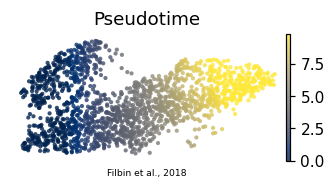

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')